# Gate Classification: KL Divergence and Cello Score

## Setup

In [1]:
## SHARED CONFIG ##

# Reload configs on each run.
import importlib

import analyse_pr_config
importlib.reload(analyse_pr_config)
from analyse_pr_config import (BARS_PNG_YMIN, FIGURE_DPI, FLOW_INVALID, FLOW_INVALID_FILE,
                               PNG_DPI, REPLICATE_MARKERS, REPLICATES, SAMPLING_METHOD,
                               replicate_mean, rpu_bands, set_rpu_scale)


## CONFIG ##

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
from scipy.special import rel_entr

from pathlib import Path

plt.rcParams["figure.dpi"] = FIGURE_DPI

OUT_DIR = Path("out")

# The one method downstream reads
RPU_COLUMN = f"RPU_{SAMPLING_METHOD}"

# the per-group sweep; off while iterating on the figure
GENERATE_PDF = True

# one PNG per group, for use outside the sweep
GENERATE_PNG = True

# Circuit shown in the inline figures
CIRCUIT = 66

# rows kept in each ranking panel
RANKING_ROWS = 5

# Inducer conditions in plate order, the bit order of gate_truth
# A = IPTG, B = aTc
CONDITIONS = ("None", "aTc", "IPTG", "Both")
# Phenotype labels depend on this order
assert CONDITIONS == REPLICATES[0]["cond_labels"]


## Load

In [2]:
# RPU per (group, replicate, condition) from analyse_pr_synthrate.ipynb
# Read back with keep_default_na=False, na_values=[""]
synthesis_rates = pd.read_csv(OUT_DIR / "analyse_pr_synthrate.csv",
                              keep_default_na=False, na_values=[""])

# Control bands and axis range, shared with the synthrate bars
WT_BAND, PL2_BAND, RPU_BAND, RPU_LIMITS = rpu_bands(synthesis_rates, RPU_COLUMN)

print(f"{len(synthesis_rates)} rows, replicates {[rep['label'] for rep in REPLICATES]}")
print(f"WT band {WT_BAND[0]:+.4f} to {WT_BAND[1]:+.4f} RPU, "
      f"pL2 band {PL2_BAND[0]:+.4f} to {PL2_BAND[1]:+.4f}")
print(f"axis {RPU_LIMITS[0]:+.4f} to {RPU_LIMITS[1]:.1f} RPU, "
      f"linear across {RPU_BAND[0]:+.4f} to {RPU_BAND[1]:+.4f}")

1140 rows, replicates ['CD1', 'CD2', 'AL1']
WT band -0.2088 to +0.0000 RPU, pL2 band -0.0572 to +0.0947
axis -3.6450 to 112.8 RPU, linear across -0.2088 to +0.0947


## Boolean Gates

In [3]:
# The 16 two-input gates: output[i] = (n >> i) & 1 over CONDITIONS
# Labels from Congrego logic_functions: A = IPTG, B = aTc
LOGIC_FUNCTIONS = [
    "false", "nor", "bnimplya", "nota",
    "animplyb", "notb", "xor", "nand",
    "and", "xnor", "b", "aimplyb",
    "a", "bimplya", "or", "true",
]

gate_truth = np.array([[(n >> i) & 1 for i in range(4)] for n in range(16)])

# false and true have no Cello score; KL scores them as one uniform row
FLAT_GATES = (0, 15)
SHAPED_GATES = [n for n in range(16) if n not in FLAT_GATES]
TRUE_FALSE_LABEL = "true/false"

# Cello flat test: 99.5th percentile of max S for a non-responding circuit
FLAT_MAX_S = 2

# Geometric mean across conditions, not the max: is the circuit generally on.
# the median geomean across all circuits
TRUE_THRESHOLD_RPU = 3.0

EPSILON = 0.01
# Ideal distributions for the KL comparison.
# ON states share the mass equally, OFF states get EPSILON each.
gate_distributions = {}
for n in SHAPED_GATES:
    on_count = gate_truth[n].sum()
    on_value = (1.0 - (4 - on_count) * EPSILON) / on_count
    gate_distributions[n] = np.where(gate_truth[n] == 1, on_value, EPSILON)
# the flat pair has no ON or OFF state to weight, so its ideal is uniform
gate_distributions[FLAT_GATES[0]] = np.full(4, 0.25)

gate_distributions

{1: array([0.97, 0.01, 0.01, 0.01]),
 2: array([0.01, 0.97, 0.01, 0.01]),
 3: array([0.49, 0.49, 0.01, 0.01]),
 4: array([0.01, 0.01, 0.97, 0.01]),
 5: array([0.49, 0.01, 0.49, 0.01]),
 6: array([0.01, 0.49, 0.49, 0.01]),
 7: array([0.33, 0.33, 0.33, 0.01]),
 8: array([0.01, 0.01, 0.01, 0.97]),
 9: array([0.49, 0.01, 0.01, 0.49]),
 10: array([0.01, 0.49, 0.01, 0.49]),
 11: array([0.33, 0.33, 0.01, 0.33]),
 12: array([0.01, 0.01, 0.49, 0.49]),
 13: array([0.33, 0.01, 0.33, 0.33]),
 14: array([0.01, 0.33, 0.33, 0.33]),
 0: array([0.25, 0.25, 0.25, 0.25])}

## Scores

In [4]:
def rpu_matrix(group):
    """[replicate, condition] RPU for one group."""
    selected = synthesis_rates[synthesis_rates["Group"] == group]
    return np.array([[float(selected[(selected["Rep"] == rep["label"])
                                     & (selected["Condition"] == condition)][RPU_COLUMN].iloc[0])
                      for condition in CONDITIONS] for rep in REPLICATES])


def level_rpu(observed):
    """Geometric mean across the four CONDITIONS: how high the circuit sits overall."""
    finite = observed[np.isfinite(observed)]
    return float(np.exp(np.log(finite).mean()))


def kl_ranking(observed):
    """(index, label, score) per gate, best first; lower D_KL is a better match."""
    fraction = observed / observed.sum()
    rows = [(n, LOGIC_FUNCTIONS[n], rel_entr(fraction, gate_distributions[n]).sum())
            for n in SHAPED_GATES]
    rows.append((FLAT_GATES[0], TRUE_FALSE_LABEL,
                 rel_entr(fraction, gate_distributions[FLAT_GATES[0]]).sum()))
    return sorted(rows, key=lambda row: row[2])


def cello_score(observed, gate):
    """Cello circuit score S = min(ON) / max(OFF) for one gate; higher is a better match.

    Nielsen et al. 2016, doi:10.1126/science.aac7341, eq. S2.
    """
    on, off = observed[gate_truth[gate] == 1], observed[gate_truth[gate] == 0]
    return on.min() / off.max()


def cello_ranking(observed):
    """(index, label, score) per shaped gate, best first; higher S is a better match."""
    return sorted(((n, LOGIC_FUNCTIONS[n], cello_score(observed, n)) for n in SHAPED_GATES),
                  key=lambda row: -row[2])


def call_by_level(observed):
    """A flat circuit is named by how high it sits, having no shape to name it by."""
    return "true" if level_rpu(observed) > TRUE_THRESHOLD_RPU else "false"


def kl_function(observed, ranking):
    """The KL phenotype: the merged flat row wins, otherwise the ranking names it."""
    if ranking[0][1] == TRUE_FALSE_LABEL:
        return call_by_level(observed)
    return ranking[0][1]


def cello_function(observed, ranking):
    """The Cello phenotype: a best S within noise names the flat pair."""
    if ranking[0][2] < FLAT_MAX_S:
        return call_by_level(observed)
    return ranking[0][1]

In [5]:
# every circuit plus pL2, the empty backbone put through the same classifier
PAGES = [f"Circuit {circuit}" for circuit in range(1, 93)] + ["pL2"]

# the classifier's input, one RPU per condition, and the conditions whose centre was imputed
observed_rpu, imputed_rpu, raw_rpu = {}, {}, {}
for group in PAGES:
    observed_rpu[group], imputed_rpu[group], raw_rpu[group] = replicate_mean(
        rpu_matrix(group), WT_BAND[0], PL2_BAND)

# A mean at or below zero is imputed as the pL2 band midpoint; logged here only
PL2_MIDPOINT = (PL2_BAND[0] + PL2_BAND[1]) / 2
for group in PAGES:
    for condition, was_imputed, before in zip(CONDITIONS, imputed_rpu[group], raw_rpu[group]):
        if was_imputed:
            print(f"IMPUTED {group:11s} {condition:5s}: arithmetic mean {before:+.4f} -> "
                  f"pL2 midpoint {PL2_MIDPOINT:+.5f}  "
                  f"(adjustment {abs(PL2_MIDPOINT - before):.4f} RPU)")
print(f"{int(sum(mask.sum() for mask in imputed_rpu.values()))} conditions imputed across "
      f"{int(sum(mask.any() for mask in imputed_rpu.values()))} groups")

# A condition with no replicate above the WT band floor excludes the circuit
CLASSIFIED = [group for group in PAGES if np.isfinite(observed_rpu[group]).all()]
EXCLUDED = [group for group in PAGES if group not in CLASSIFIED]

for group in EXCLUDED:
    missing = [condition for condition, value in zip(CONDITIONS, observed_rpu[group])
               if not np.isfinite(value)]
    print(f"WARNING {group} excluded: no usable replicate for {', '.join(missing)}")
print(f"{len(CLASSIFIED)} of {len(PAGES)} groups classified, {len(EXCLUDED)} excluded")

IMPUTED Circuit 11  None : arithmetic mean -0.0518 -> pL2 midpoint +0.01876  (adjustment 0.0706 RPU)
IMPUTED Circuit 53  IPTG : arithmetic mean -0.0525 -> pL2 midpoint +0.01876  (adjustment 0.0713 RPU)
IMPUTED Circuit 53  Both : arithmetic mean -0.0092 -> pL2 midpoint +0.01876  (adjustment 0.0279 RPU)
IMPUTED Circuit 54  None : arithmetic mean -0.0105 -> pL2 midpoint +0.01876  (adjustment 0.0293 RPU)
IMPUTED Circuit 64  None : arithmetic mean -0.0014 -> pL2 midpoint +0.01876  (adjustment 0.0201 RPU)
IMPUTED Circuit 72  IPTG : arithmetic mean -0.0507 -> pL2 midpoint +0.01876  (adjustment 0.0694 RPU)
IMPUTED Circuit 72  Both : arithmetic mean -0.0515 -> pL2 midpoint +0.01876  (adjustment 0.0703 RPU)
IMPUTED pL2         IPTG : arithmetic mean -0.0232 -> pL2 midpoint +0.01876  (adjustment 0.0419 RPU)
IMPUTED pL2         Both : arithmetic mean -0.0091 -> pL2 midpoint +0.01876  (adjustment 0.0279 RPU)
9 conditions imputed across 6 groups
93 of 93 groups classified, 0 excluded


In [6]:
group = f"Circuit {CIRCUIT}"
assert group in CLASSIFIED, f"{group} is excluded from the classification; pick another"

observed = observed_rpu[group]
kl_rows, cello_rows = kl_ranking(observed), cello_ranking(observed)

print(f"{group}  geometric mean RPU: "
      + "  ".join(f"{c}={v:.3f}" for c, v in zip(CONDITIONS, observed)))
print(f"  max {observed.max():.3f} RPU")
print(f"  KL     {kl_function(observed, kl_rows)}: "
      f"{kl_rows[0][1]} at D_KL={kl_rows[0][2]:.4f}")
print(f"  Cello  {cello_function(observed, cello_rows)}: "
      f"{cello_rows[0][1]} at S={cello_rows[0][2]:.3f}")

display(pd.DataFrame({"function": [label for _, label, _ in kl_rows],
                      "truth": ["".join(map(str, gate_truth[n])) for n, _, _ in kl_rows],
                      "D_KL": [round(score, 4) for _, _, score in kl_rows]}))
pd.DataFrame({"function": [label for _, label, _ in cello_rows],
              "truth": ["".join(map(str, gate_truth[n])) for n, _, _ in cello_rows],
              "S": [round(score, 3) for _, _, score in cello_rows]})

Circuit 66  geometric mean RPU: None=2.221  aTc=2.603  IPTG=0.996  Both=0.700
  max 2.603 RPU
  KL     false: true/false at D_KL=0.1262
  Cello  nota: nota at S=2.230


,function,truth,D_KL
0,true/false,0000,0.1262
1,nand,1110,0.2241
2,aimplyb,1101,0.3827
3,nota,1100,0.4659
4,or,0111,1.0395
5,xor,0110,1.1969
6,bimplya,1011,1.2444
7,b,0101,1.3734
8,notb,1010,1.4249
9,bnimplya,0100,1.5188


,function,truth,S
0,nota,1100,2.230
1,nand,1110,1.422
2,bnimplya,0100,1.172
3,nor,1000,0.853
4,aimplyb,1101,0.703
5,xor,0110,0.449
6,animplyb,0010,0.383
7,notb,1010,0.383
8,b,0101,0.315
9,or,0111,0.315


## Gate Calls

In [7]:
# Built outside the PDF gate
rows = []
for group in PAGES:
    # an excluded group holds its row and carries NaN in every other column
    if group in EXCLUDED:
        rows.append({"Group": group})
        continue
    observed = observed_rpu[group]
    kl_rows, cello_rows = kl_ranking(observed), cello_ranking(observed)
    # flow cytometry shows no steady-state Boolean output, so neither ranking is a usable call
    if group in FLOW_INVALID:
        kl_call = cello_call = "invalid"
    else:
        kl_call = kl_function(observed, kl_rows)
        cello_call = cello_function(observed, cello_rows)
    rows.append({"Group": group,
                 "logical_function_kl": kl_call,
                 "logical_function_cello": cello_call,
                 "level_rpu": round(level_rpu(observed), 3),
                 "max_rpu": round(float(observed.max()), 3),
                 # the classifier's input, the four means the calls above were read off
                 **{f"{condition}_rpu": round(float(value), 3)
                    for condition, value in zip(CONDITIONS, observed)},
                 **{f"D_KL_{label}": round(score, 4) for _, label, score in kl_rows},
                 **{f"S_{label}": round(score, 3) for _, label, score in cello_rows}})

# CONDITIONS order, so the four read left to right as the truth-table index
condition_columns = [f"{condition}_rpu" for condition in CONDITIONS]

# phenotype order, not the per-row ranked order the dicts above carry
score_columns = ([f"D_KL_{LOGIC_FUNCTIONS[n]}" for n in SHAPED_GATES]
                 + [f"D_KL_{TRUE_FALSE_LABEL}"]
                 + [f"S_{LOGIC_FUNCTIONS[n]}" for n in SHAPED_GATES])

# Read back with keep_default_na=False, na_values=[""]
calls = pd.DataFrame(rows, columns=["Group", "logical_function_kl", "logical_function_cello",
                                    "level_rpu", "max_rpu"]
                                   + condition_columns + score_columns)
calls.to_csv(OUT_DIR / "analyse_pr_classify.csv", index=False)

print(f"{len(FLOW_INVALID)} groups called invalid from {FLOW_INVALID_FILE.name}: "
      + ", ".join(sorted(FLOW_INVALID, key=lambda g: int(g.split()[1]))))

classified = calls.dropna(subset=["logical_function_kl"])
print(pd.crosstab(classified["logical_function_kl"], classified["logical_function_cello"],
                  margins=True, margins_name="all").to_string())

# Parallel scores; not expected to converge
for criterion in ("kl", "cello"):
    flat = classified[f"logical_function_{criterion}"].isin(["true", "false"])
    print(f"\n{criterion}: {int(flat.sum())} of {len(classified)} flat "
          f"({int((classified[f'logical_function_{criterion}'] == 'true').sum())} true, "
          f"{int((classified[f'logical_function_{criterion}'] == 'false').sum())} false)")

6 groups called invalid from flow_invalid.txt: Circuit 10, Circuit 19, Circuit 20, Circuit 31, Circuit 51, Circuit 86
logical_function_cello   a  and  b  false  invalid  nota  or  true  all
logical_function_kl                                                    
a                       32    0  0      0        0     0   0     0   32
aimplyb                  0    0  0      0        0     1   0     0    1
false                    0    1  1     18        0     3   0     0   23
invalid                  0    0  0      0        6     0   0     0    6
nand                     0    0  0      0        0     1   0     0    1
nota                     0    0  0      0        0    13   0     0   13
or                       1    0  0      0        0     0   2     0    3
true                     1    0  0      0        0     2   0    11   14
all                     34    1  1     18        6    20   2    11   93

kl: 37 of 93 flat (14 true, 23 false)

cello: 29 of 93 flat (11 true, 18 false)


## Circuit Figure

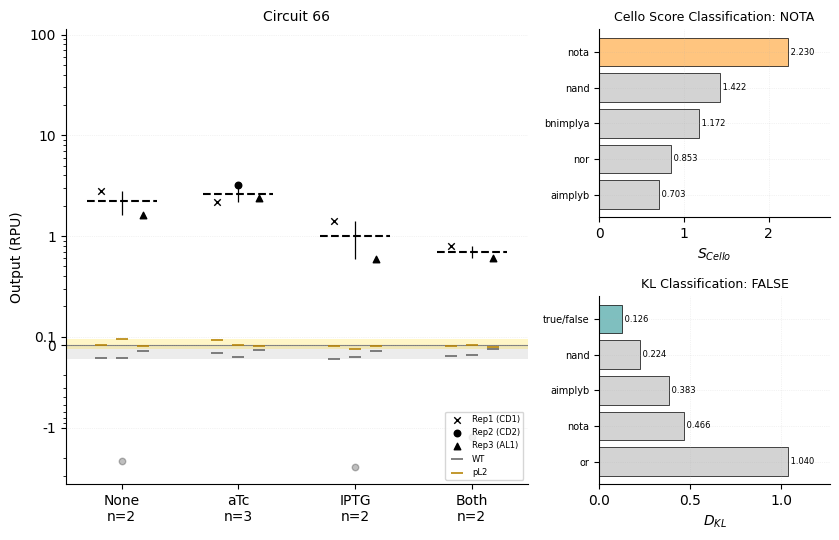

In [8]:
def plot_classification(group, ylim=RPU_LIMITS):
    """One row: RPU bars, then the D_KL and Cello rankings."""
    matrix = rpu_matrix(group)
    # the centre takes every replicate at or above the WT band floor, so n counts those
    included = np.sum(matrix >= WT_BAND[0], axis=0)
    # Below-floor replicates excluded from the centre
    invalid = np.isfinite(matrix) & (matrix < WT_BAND[0])
    drawn = np.where(invalid, np.nan, matrix)
    observed, _imputed, _raw = replicate_mean(matrix, WT_BAND[0], PL2_BAND)
    kl_rows = kl_ranking(observed)[:RANKING_ROWS]
    cello_rows = cello_ranking(observed)[:RANKING_ROWS]
    flow_invalid = group in FLOW_INVALID

    # RPU panel spans both rows
    figure = plt.figure(figsize=(8.5, 5.5))
    grid = figure.add_gridspec(2, 2, width_ratios=[2, 1])
    ax_rpu = figure.add_subplot(grid[:, 0])
    ax_cello = figure.add_subplot(grid[0, 1])
    ax_kl = figure.add_subplot(grid[1, 1])

    ## --- RPU bars, matching analyse_pr_synthrate_bars.pdf ---
    centres = np.arange(4)
    ax_rpu.axhspan(*WT_BAND, color="gray", alpha=0.15, zorder=0, linewidth=0)
    # drawn second so the narrower band stays visible where the two overlap
    ax_rpu.axhspan(*PL2_BAND, color="gold", alpha=0.22, zorder=0, linewidth=0)
    ax_rpu.vlines(centres, np.nanmin(drawn, axis=0), np.nanmax(drawn, axis=0),
                  color="black", lw=0.9, zorder=2)
    # Imputed centres drawn like any other
    ax_rpu.hlines(observed, centres - 0.3, centres + 0.3, color="black", lw=1.5, ls="--",
                  zorder=2)
    for row, (rep, marker, offset) in enumerate(zip(REPLICATES, REPLICATE_MARKERS,
                                                    [-0.18, 0.0, 0.18])):
        ax_rpu.scatter(centres + offset, drawn[row], marker=marker, color="black", s=22,
                       linewidths=1.0, zorder=3, label=f"{rep['tag']} ({rep['label']})")
        # Rejected replicates kept visible
        ax_rpu.scatter(centres + offset, np.where(invalid[row], matrix[row], np.nan),
                       marker=marker, color="black", s=22, linewidths=1.0, alpha=0.25,
                       zorder=3)
    # Both control bands, each in its own colour
    for control, control_colour in (("WT", "dimgray"), ("pL2", "darkgoldenrod")):
        control_matrix = rpu_matrix(control)
        for row, offset in enumerate([-0.18, 0.0, 0.18]):
            ax_rpu.scatter(centres + offset, control_matrix[row], marker="_",
                           color=control_colour, s=70, linewidths=1.2, zorder=2,
                           label=control if row == 0 else None)
    ax_rpu.axhline(0, color="gray", lw=0.8, zorder=0)
    set_rpu_scale(ax_rpu, RPU_BAND, RPU_LIMITS)
    # One range across the sweep
    ax_rpu.set_ylim(*ylim)
    ax_rpu.set_xticks(centres)
    ax_rpu.set_xticklabels([f"{condition}\nn={count}"
                            for condition, count in zip(CONDITIONS, included)])
    ax_rpu.set_ylabel("Output (RPU)")
    ax_rpu.set_title(group, fontsize=10)
    ax_rpu.legend(fontsize=6, loc="lower right")
    ax_rpu.grid(True, axis="y", ls=":", alpha=0.3, linewidth=0.5)

    ## --- rankings, best at the top: Cello S above, D_KL below ---
    # Top bar filled where the phenotype came from
    for ax, ranked, phenotype, from_ranking, winner, name, xlabel in (
            (ax_cello, cello_rows, cello_function,
             cello_rows[0][2] >= FLAT_MAX_S and not flow_invalid,
             to_rgba("darkorange", 0.5), "Cello Score Classification", "$S_{Cello}$"),
            (ax_kl, kl_rows, kl_function, not flow_invalid,
             to_rgba("teal", 0.5), "KL Classification", "$D_{KL}$")):
        call = "invalid" if flow_invalid else phenotype(observed, ranked)
        scores = [score for _, _, score in ranked]
        colours = ["lightgray"] * len(ranked)
        if from_ranking:
            # the alpha rides in the face colour so the edge stays opaque
            colours[0] = winner
        ax.barh(range(len(ranked)), scores, color=colours, edgecolor="black", linewidth=0.5)
        ax.set_yticks(range(len(ranked)))
        ax.set_yticklabels([label for _, label, _ in ranked], fontsize=7)
        ax.invert_yaxis()
        ax.set_title(f"{name}: {call.upper()}", fontsize=9)
        ax.set_xlabel(xlabel)
        # room for the per-bar labels, which sit outside their bars
        ax.set_xlim(0, max(scores) * 1.22)
        for position, score in enumerate(scores):
            ax.text(score, position, f" {score:.3f}", va="center", fontsize=6)
        ax.grid(True, ls=":", alpha=0.3, linewidth=0.5)

    for ax in (ax_rpu, ax_kl, ax_cello):
        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)

    figure.tight_layout()
    return figure


_ = plot_classification(f"Circuit {CIRCUIT}")
plt.show()

## All Circuits

In [9]:
import time
from matplotlib.backends.backend_pdf import PdfPages

if not GENERATE_PDF:
    print("GENERATE_PDF is False: skipping the per-circuit PDF")
else:
    path = OUT_DIR / "analyse_pr_classify.pdf"
    started = time.perf_counter()
    with PdfPages(path) as pdf:
        for group in CLASSIFIED:
            figure = plot_classification(group)
            pdf.savefig(figure, dpi=72)
            plt.close(figure)
    print(f"{path}: {len(CLASSIFIED)} pages, {time.perf_counter() - started:.0f}s, "
          f"{path.stat().st_size / 1e6:.1f} MB")

out/analyse_pr_classify.pdf: 93 pages, 28s, 0.6 MB


In [10]:
# One PNG per classified group; floor lifted to BARS_PNG_YMIN

if not GENERATE_PNG:
    print("GENERATE_PNG is False: skipping the per-group PNGs")
else:
    png_dir = OUT_DIR / "analyse_pr_classify"
    png_dir.mkdir(parents=True, exist_ok=True)
    started = time.perf_counter()
    for group in CLASSIFIED:
        figure = plot_classification(group, ylim=(BARS_PNG_YMIN, RPU_LIMITS[1]))
        # Zero-padded so files sort in circuit order
        stem = f"circuit_{int(group.split()[1]):02d}" if group.startswith("Circuit") else group
        figure.savefig(png_dir / f"{stem}.png", dpi=PNG_DPI)
        plt.close(figure)
    print(f"{png_dir}: {len(CLASSIFIED)} PNGs, {time.perf_counter() - started:.0f}s")

out/analyse_pr_classify: 93 PNGs, 38s
